# 07 · What it costs: interval-triggered vs point-triggered maintenance, in euros

**Question (H2-H3, tutor's framing).** Acting on an interval is more cautious than acting on a point prediction. Above which failure : planned cost ratio does that caution pay for itself, and what is that in euros?

**Maintenance model** (`src/decision.py`). The first alert at cycle *t* books a removal at *t + h* (h = cycles of notice: 10 or 30). Planned if the engine is still alive, otherwise it fails. Cost = failures × ratio + planned removals, divided by cycles flown (renewal-reward cost rate), so wasted life counts. Units: one planned removal; × `PLANNED_REMOVAL_EUR` (€1.0 M, a CFM56-class shop visit) for euros.

**Rules.** Every *tuned* rule chooses its dial on the calibration engines for the given ratio, then is applied once to the evaluation engines (no peeking).

| rule | alerts when | dial |
|---|---|---|
| age (tuned) | cycle ≥ age − h | replacement age (business baseline, no sensors) |
| point | prediction ≤ h | none (acting on the raw prediction) |
| point + tuned margin | prediction ≤ h + m | m, tuned: **the honest baseline** |
| SCP / Mondrian / CQR 90 % | lower bound of the 90 % interval ≤ h | fixed at 90 % |
| … cost-matched | lower bound at level 1 − 2/(1 + ratio) ≤ h | set by the textbook critical ratio |
| … tuned level | lower bound ≤ h | level, tuned |
| oracle | true RUL ≤ h | perfect information (floor) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import summarize as S
from src.config import CONFIDENCE_LEVEL, PLANNED_REMOVAL_EUR
from src.plots import save

pd.set_option("display.width", 180)
pd.set_option("display.precision", 3)
R = S.load()
{k: len(v) for k, v in R.items()}

{'accuracy': 80, 'coverage': 2200, 'decisions': 13680, 'curves': 46240}

## Cost per 1,000 cycles (median over subsets × seeds), LightGBM, h = 10

In [2]:
dec = R["decisions"]
RULES = ["age (tuned)", "point", "point + tuned margin", "SCP 90%", "Mondrian 90%", "CQR 90%",
         "Mondrian cost-matched", "CQR cost-matched", "Mondrian tuned level", "CQR tuned level", "oracle"]
t10 = S.cost_table(dec, horizon=10).reindex(RULES)
t10.round(2)

ratio,1.0,1.5,2.0,3.0,5.0,10.0,20.0,50.0,100.0
rule,,,,,,,,,
age (tuned),4.50,6.39,7.14,7.44,7.95,8.75,10.17,15.12,23.05
point,4.51,5.74,6.97,9.44,14.37,26.69,51.34,125.05,247.99
point + tuned margin,4.51,4.89,4.97,5.29,5.47,5.94,7.11,10.35,16.06
SCP 90%,5.20,5.20,5.20,5.20,5.20,5.24,5.34,5.62,5.65
Mondrian 90%,5.32,5.32,5.32,5.33,5.43,5.56,5.74,6.09,7.15
CQR 90%,4.75,4.85,4.94,5.14,5.41,6.19,7.94,13.26,22.37
Mondrian cost-matched,4.51,5.51,6.34,7.22,8.50,7.02,5.74,5.71,5.89
CQR cost-matched,4.45,6.58,8.38,10.61,11.37,10.15,7.65,5.49,5.39
Mondrian tuned level,4.51,4.97,5.23,5.29,5.39,5.73,6.35,8.25,11.81


In [3]:
t30 = S.cost_table(dec, horizon=30).reindex(RULES)
t30.round(2)

ratio,1.0,1.5,2.0,3.0,5.0,10.0,20.0,50.0,100.0
rule,,,,,,,,,
age (tuned),4.50,6.39,7.14,7.44,7.95,8.75,10.17,15.12,23.05
point,4.54,5.90,7.24,9.93,15.31,28.76,55.65,136.34,270.80
point + tuned margin,4.54,5.28,5.59,6.07,6.65,7.80,9.55,14.15,22.39
SCP 90%,5.21,5.38,5.56,5.92,6.67,8.61,12.50,24.16,43.60
Mondrian 90%,5.43,5.52,5.63,5.91,6.46,7.85,10.56,18.68,32.22
CQR 90%,5.07,5.27,5.49,5.95,6.81,8.98,13.32,26.85,49.14
Mondrian cost-matched,4.54,5.72,6.52,7.62,8.53,9.17,10.22,12.11,14.45
CQR cost-matched,4.48,6.08,6.95,7.58,8.97,11.37,13.11,13.67,12.24
Mondrian tuned level,4.54,5.27,5.60,6.08,6.78,7.64,9.36,14.30,23.59


## Failures per 100 engines (median), h = 10

In [4]:
f = S.with_model_free(dec).assign(fail_per_100=lambda d: 100 * d["failures"] / d["engines"])
f[(f["model"] == "lgbm") & (f["horizon"] == 10)].pivot_table(index="rule", columns="ratio", values="fail_per_100", aggfunc="median").reindex(RULES).round(1)

ratio,1.0,1.5,2.0,3.0,5.0,10.0,20.0,50.0,100.0
rule,,,,,,,,,
age (tuned),97.0,42.2,14.9,6.1,4.0,2.8,2.2,2.2,2.2
point,53.1,53.1,53.1,53.1,53.1,53.1,53.1,53.1,53.1
point + tuned margin,53.1,4.6,3.0,3.0,2.4,2.4,2.4,2.4,2.4
SCP 90%,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Mondrian 90%,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4,0.4
CQR 90%,4.2,4.2,4.2,4.2,4.2,4.2,4.2,4.2,4.2
Mondrian cost-matched,53.1,44.8,38.0,30.6,21.2,5.0,0.4,0.0,0.0
CQR cost-matched,100.0,100.0,92.8,70.3,36.3,13.9,3.8,0.0,0.0
Mondrian tuned level,53.1,6.0,3.0,2.0,1.8,1.3,1.3,1.3,1.3


## In euros: from which failure cost does an interval pay off?

For each of the 40 runs (4 subsets x 10 seeds) the break-even is the cost ratio above which the challenger stays cheaper than the tuned safety margin; a run that never breaks even counts as infinite. A planned removal is set at €1.0 M (`PLANNED_REMOVAL_EUR`), so the ratio reads as the failure cost in millions of euros.

In [5]:
be_runs = S.break_even_runs(dec, "point + tuned margin", ["SCP 90%", "Mondrian 90%", "CQR 90%", "Mondrian tuned level", "CQR tuned level", "Mondrian cost-matched", "CQR cost-matched"])
be_runs.round(2)

,horizon,challenger,runs,runs_breaking_even,median,q25,q75,median_failure_cost_eur,median_if_breaking_even
0,10,SCP 90%,40,40,4.39,3.20,6.13,4.388e+06,4.52
1,30,SCP 90%,40,10,inf,3.02,inf,inf,1.64
2,10,Mondrian 90%,40,38,5.53,3.94,8.04,5.531e+06,5.45
3,30,Mondrian 90%,40,14,inf,2.40,inf,inf,2.02
4,10,CQR 90%,40,13,inf,1.73,inf,inf,1.60
5,30,CQR 90%,40,4,inf,inf,inf,inf,1.53
6,10,Mondrian tuned level,40,31,5.55,2.80,14.07,5.548e+06,3.63
7,30,Mondrian tuned level,40,20,21.47,2.17,inf,2.147e+07,2.34
8,10,CQR tuned level,40,26,2.14,0.00,inf,2.142e+06,0.00
9,30,CQR tuned level,40,27,4.99,1.58,inf,4.991e+06,2.16


## Per subset: break-even among the seeds that break even (`seeds_breaking_even` says how many)

In [6]:
challengers = ["SCP 90%", "Mondrian 90%", "CQR 90%", "Mondrian tuned level", "CQR tuned level", "Mondrian cost-matched", "CQR cost-matched"]
be = pd.concat([S.break_even_summary(dec, "point + tuned margin", c) for c in challengers], ignore_index=True)
be[be["model"] == "lgbm"].sort_values(["horizon", "challenger", "subset"]).round(2)

,subset,model,horizon,baseline,challenger,seeds,seeds_breaking_even,median_break_even,min,max,failure_cost_eur_at_break_even
32,FD001,lgbm,10,point + tuned margin,CQR 90%,10.0,7.0,1.63,1.34,1.75,1.627e+06
34,FD002,lgbm,10,point + tuned margin,CQR 90%,10.0,0.0,NaN,NaN,NaN,NaN
36,FD003,lgbm,10,point + tuned margin,CQR 90%,10.0,6.0,1.49,1.24,2.01,1.488e+06
38,FD004,lgbm,10,point + tuned margin,CQR 90%,10.0,0.0,NaN,NaN,NaN,NaN
80,FD001,lgbm,10,point + tuned margin,CQR cost-matched,10.0,10.0,15.77,10.67,20.70,1.577e+07
82,FD002,lgbm,10,point + tuned margin,CQR cost-matched,10.0,10.0,34.49,28.90,83.78,3.449e+07
84,FD003,lgbm,10,point + tuned margin,CQR cost-matched,10.0,10.0,15.27,8.32,24.42,1.527e+07
86,FD004,lgbm,10,point + tuned margin,CQR cost-matched,10.0,10.0,26.38,18.09,44.00,2.638e+07
56,FD001,lgbm,10,point + tuned margin,CQR tuned level,10.0,7.0,0.00,0.00,2.53,0.000e+00
58,FD002,lgbm,10,point + tuned margin,CQR tuned level,10.0,6.0,2.30,0.00,3.65,2.304e+06


## Share of seeds in which the challenger is cheaper (LightGBM)

In [7]:
for c in ["CQR 90%", "Mondrian 90%", "CQR tuned level"]:
    w = S.win_rate(dec, "point + tuned margin", c)
    print(c); display(w.xs("lgbm", level="model").round(1))

CQR 90%


ratio           1.0    1.5    2.0    3.0    5.0    10.0   20.0   50.0   100.0
subset horizon                                                               
FD001  10         0.0    0.2    0.7    0.7    0.7    0.7    0.7    0.7    0.7
       30         0.0    0.3    1.0    1.0    0.8    0.3    0.2    0.2    0.2
FD002  10         0.0    0.1    0.0    0.0    0.0    0.0    0.0    0.0    0.0
       30         0.0    0.7    0.9    0.7    0.2    0.0    0.0    0.0    0.0
FD003  10         0.0    0.3    0.5    0.6    0.6    0.6    0.6    0.6    0.6
       30         0.0    0.4    0.7    0.4    0.2    0.2    0.2    0.2    0.2
FD004  10         0.0    0.4    0.3    0.2    0.0    0.0    0.0    0.0    0.0
       30         0.0    0.7    0.5    0.0    0.0    0.0    0.0    0.0    0.0

Mondrian 90%


ratio           1.0    1.5    2.0    3.0    5.0    10.0   20.0   50.0   100.0
subset horizon                                                               
FD001  10         0.0    0.0    0.0    0.1    0.7    0.9    1.0    1.0    1.0
       30         0.0    0.0    0.3    0.9    0.9    0.3    0.2    0.2    0.2
FD002  10         0.0    0.0    0.0    0.0    0.1    0.6    0.8    0.9    0.9
       30         0.0    0.0    0.1    0.8    0.8    0.2    0.0    0.0    0.0
FD003  10         0.0    0.0    0.0    0.1    0.5    1.0    1.0    1.0    1.0
       30         0.0    0.0    0.5    0.8    0.9    0.9    0.9    0.9    0.9
FD004  10         0.0    0.0    0.0    0.1    0.4    0.7    0.7    0.9    0.9
       30         0.0    0.1    0.5    0.8    0.6    0.5    0.5    0.3    0.3

CQR tuned level


ratio           1.0    1.5    2.0    3.0    5.0    10.0   20.0   50.0   100.0
subset horizon                                                               
FD001  10         1.0    0.6    0.6    0.7    0.7    0.7    0.7    0.7    0.7
       30         1.0    0.5    0.8    1.0    1.0    0.9    0.8    0.7    0.6
FD002  10         1.0    0.2    0.5    0.5    0.6    0.6    0.6    0.6    0.6
       30         1.0    0.9    0.9    0.8    0.8    0.8    0.7    0.5    0.5
FD003  10         1.0    0.6    0.6    0.6    0.7    0.7    0.7    0.7    0.7
       30         1.0    0.8    0.8    0.7    0.8    0.7    0.7    0.7    0.7
FD004  10         1.0    0.8    0.6    0.6    0.6    0.6    0.6    0.6    0.6
       30         1.0    0.8    0.5    0.5    0.4    0.7    0.9    0.9    0.9

## Value captured: share of the age → perfect-information saving each rule achieves

In [8]:
v = S.add_value_captured(dec)
v[(v["model"] == "lgbm") & (v["horizon"] == 10)].pivot_table(index="rule", columns="ratio", values="value_captured", aggfunc="median").reindex(RULES).round(2)

ratio,1.0,1.5,2.0,3.0,5.0,10.0,20.0,50.0,100.0
rule,,,,,,,,,
age (tuned),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
point,-1.29,0.32,0.06,-0.54,-1.63,-3.86,-6.73,-9.97,-12.00
point + tuned margin,-1.29,0.80,0.83,0.81,0.77,0.68,0.59,0.40,0.34
SCP 90%,-31.96,0.61,0.71,0.75,0.79,0.84,0.88,0.93,0.96
Mondrian 90%,-35.85,0.59,0.70,0.73,0.76,0.78,0.81,0.83,0.84
CQR 90%,-13.48,0.80,0.83,0.80,0.73,0.56,0.31,0.11,-0.02
Mondrian cost-matched,-1.29,0.44,0.32,0.09,-0.14,0.43,0.81,0.89,0.93
CQR cost-matched,1.00,-0.13,-0.44,-0.92,-0.86,-0.28,0.41,0.94,0.95
Mondrian tuned level,-1.29,0.76,0.80,0.79,0.77,0.74,0.72,0.70,0.68


## Figures

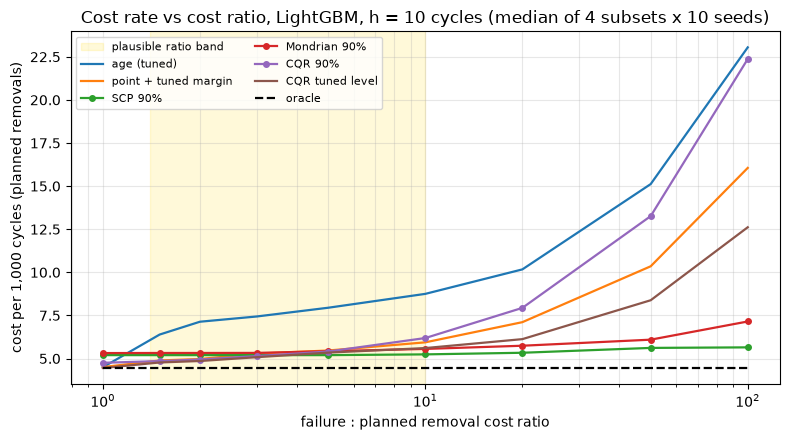

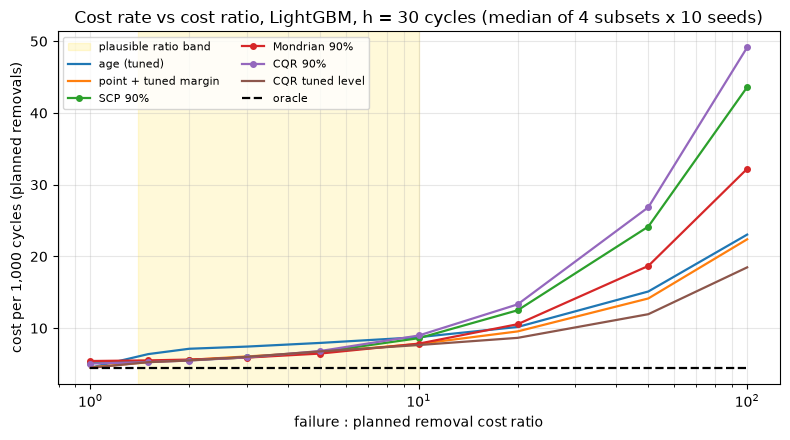

In [9]:
from src.plots import plot_cost_curves, plot_dial_tradeoff
show = ["age (tuned)", "point + tuned margin", "SCP 90%", "Mondrian 90%", "CQR 90%", "CQR tuned level", "oracle"]
for h, t in ((10, t10), (30, t30)):
    fig = plot_cost_curves(t, f"Cost rate vs cost ratio, LightGBM, h = {h} cycles (median of 4 subsets x 10 seeds)",
                           band=S.REALISTIC_BAND, rules=show)
    save(fig, f"crossfit_cost_curves_h{h}.png")

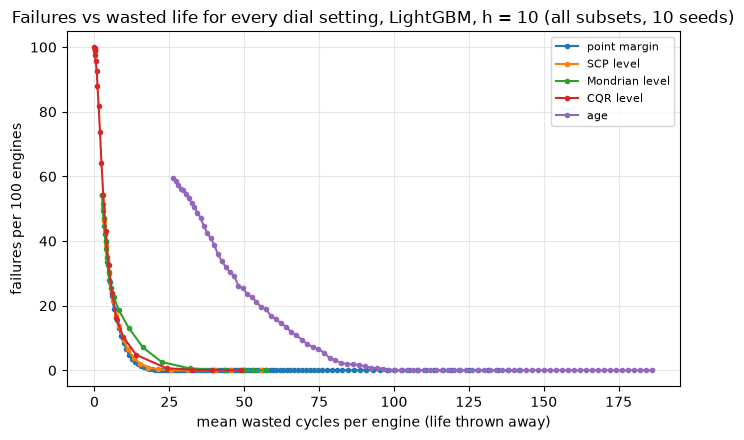

In [10]:
cur = R["curves"]
pts = {}
for dial in ["point margin", "SCP level", "Mondrian level", "CQR level"]:
    c = cur[(cur["model"] == "lgbm") & (cur["horizon"] == 10) & (cur["dial"] == dial)]
    pts[dial] = c.groupby("value")[["failures", "wasted_cycles", "engines"]].sum().reset_index()
age = cur[(cur["dial"] == "age") & (cur["horizon"] == 10)].groupby("value")[["failures", "wasted_cycles", "engines"]].sum().reset_index()
pts["age"] = age[age["failures"] / age["engines"] < 0.6]
fig = plot_dial_tradeoff(pts, "Failures vs wasted life for every dial setting, LightGBM, h = 10 (all subsets, 10 seeds)")
save(fig, "crossfit_dial_tradeoff_h10.png")

## Behavioural angle: what does it cost to let a planner move the dial?

Planners use an algorithm more when they can adjust it a little (Dietvorst, Simmons & Massey 2018). The curves give the price of that freedom: start from the cost-optimal setting (chosen with hindsight on the evaluation engines, so this is a best case) and move the dial by a bounded amount in the cautious or the risky direction.

In [11]:
def override_cost(cur, dial, steps, ratio, horizon=10, model="lgbm"):
    c = cur[(cur["dial"] == dial) & (cur["horizon"] == horizon) & (cur["model"] == model)]
    agg = c.groupby("value")[["failures", "planned", "cycles_flown"]].sum().reset_index()
    cost = 1000 * (ratio * agg["failures"] + agg["planned"]) / agg["cycles_flown"]
    vals = agg["value"].to_numpy(); best = int(np.argmin(cost.to_numpy()))
    rows = []
    for s in steps:
        j = int(np.clip(best + s, 0, len(vals) - 1))
        rows.append({"dial": dial, "ratio": ratio, "step": s, "setting": vals[j], "extra_cost_%": 100 * (cost[j] / cost[best] - 1)})
    return pd.DataFrame(rows)

steps = [-10, -5, -2, -1, 0, 1, 2, 5, 10]
ov = pd.concat([override_cost(cur, d, steps, r) for d in ["point margin", "Mondrian level", "CQR level"] for r in (2, 5, 10)])
ov.pivot_table(index=["dial", "ratio"], columns="step", values="extra_cost_%").round(1)

step                    -10    -5    -2    -1    0    1    2     5     10
dial           ratio                                                     
CQR level      2       69.0   30.3   7.6   3.3  0.0  0.8  4.8  14.4  14.4
               5      274.4  105.0  29.1  10.7  0.0  2.5  5.6  11.3  11.3
               10     610.9  239.4  71.4  29.1  0.0  0.2  2.7   8.0   8.0
Mondrian level 2       23.0   13.1   4.7   1.3  0.0  2.8  8.9  17.6  17.6
               5      105.4   65.1  16.0   2.8  0.0  4.2  7.6  12.3  12.3
               10     245.2  156.2  43.8  11.6  0.0  1.5  4.6   9.2   9.2
point margin   2       12.6    2.8   0.3   0.1  0.0  0.1  0.3   1.3   3.5
               5       26.5    3.9   0.4   0.3  0.0  0.1  0.3   1.2   3.6
               10      24.3    2.5   0.2   0.0  0.0  0.1  0.3   1.5   4.2

Steps are grid steps: 1 cycle of margin, or one step on the level grid (0.05 up to 0.95, then 0.97, 0.98, 0.99). Negative = riskier (later alerts), positive = more cautious.

## Reading (FD001-FD004, 10 seeds, LightGBM)

* **Acting on the raw prediction is not an option**: 53 failures per 100 engines at 10 cycles of notice.
* **The tuned safety margin is a strong baseline but over-fits.** Tuned on 20-52 calibration engines, it picks the smallest margin that avoided failures there, and about 1 in (n + 1) new engines needs more: 2.4-3 failures per 100 at every ratio.
* **10 cycles of notice.** A fixed 90 % split-conformal interval (0 failures, 31 cycles wasted per engine) becomes cheaper than the tuned margin above a median ratio of **4.4 : 1** (half the runs between 3.2 and 6.1), so above about **€4.4 M per failure** at a €1.0 M planned removal, and it breaks even in all 40 runs. Mondrian 90 %: 5.5 : 1 (38 of 40 runs). CQR with a tuned level breaks even earliest when it does (median 2.1 : 1) but only in 26 of 40 runs. CQR at a fixed 90 % works on the one-condition subsets (about 1.5 : 1) but not on FD002/FD004.
* **30 cycles of notice.** Fixed 90 % intervals let 5-9 engines in 100 fail (the late misses of notebook 06) and lose their advantage above about 5 : 1. Only CQR with a tuned level still breaks even in most runs (median 5.0 : 1, 27 of 40 runs). More notice needs a higher confidence level, not a different model.
* **The textbook level is too low.** Setting the level from the critical ratio (cost-matched) under-protects at moderate ratios (Mondrian at 5 : 1 lets 21 in 100 fail), because the formula prices acting early as a whole removal, while here it only costs some wasted life. It is competitive only above 20 : 1.
* **Planner overrides (H6).** Moving the safety margin by ± 2 cycles costs under 0.5 %, by ± 5 cycles under 4 %. On the confidence level the cost is asymmetric: one step more cautious costs 0.2-4 %, one step riskier 1-29 %. Give planners freedom towards caution and a hard limit towards risk.